### 1.Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

print("Libraries Imported Successfully!")

Libraries Imported Successfully!


### 2.Load Dataset

In [2]:
df = pd.read_csv("Unemployment in India.csv")
print("Dataset Loaded Successfully!")
df.head()

Dataset Loaded Successfully!


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


### 3.Shape Inspection

In [3]:
print("Dataset Shape:", df.shape)

print("\nNumber of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include="all"))

Dataset Shape: (768, 7)

Number of Rows: 768
Number of Columns: 7

Column Names:
['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    str    
 1    Date                                     740 non-null    str    
 2    Frequency                                740 non-null    str    
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    str    
dtypes: float64(3), 

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
count,740,740,740,740.000000,7.400000e+02,740.000000,740
unique,28,14,2,NaN,NaN,NaN,2
top,Andhra Pradesh,31-10-2019,Monthly,NaN,NaN,NaN,Urban
freq,28,55,381,NaN,NaN,NaN,381
mean,NaN,NaN,NaN,11.787946,7.204460e+06,42.630122,NaN
std,NaN,NaN,NaN,10.721298,8.087988e+06,8.111094,NaN
min,NaN,NaN,NaN,0.000000,4.942000e+04,13.330000,NaN
25%,NaN,NaN,NaN,4.657500,1.190404e+06,38.062500,NaN
50%,NaN,NaN,NaN,8.350000,4.744178e+06,41.160000,NaN
75%,NaN,NaN,NaN,15.887500,1.127549e+07,45.505000,NaN


### 4.Null Value Check

In [4]:
print("Null Values in Each Column:")
print(df.isnull().sum())
print("\nTotal Null Values:", df.isnull().sum().sum())
print("\nDuplicate Rows:", df.duplicated().sum())

Null Values in Each Column:
Region                                      28
 Date                                       28
 Frequency                                  28
 Estimated Unemployment Rate (%)            28
 Estimated Employed                         28
 Estimated Labour Participation Rate (%)    28
Area                                        28
dtype: int64

Total Null Values: 196

Duplicate Rows: 27


### 5.Data Cleaning & Type Conversion

In [5]:
# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Remove extra spaces from text columns
df["Region"] = df["Region"].astype("string").str.strip()
df["Area"] = df["Area"].astype("string").str.strip()
df["Frequency"] = df["Frequency"].astype("string").str.strip()

# Convert Date column
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True, errors="coerce")

# Convert numerical columns
numeric_columns = ["Estimated Unemployment Rate (%)", "Estimated Employed", "Estimated Labour Participation Rate (%)"]
for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove rows with missing important values
df.dropna(subset=["Region", "Date", "Estimated Unemployment Rate (%)", "Estimated Employed", "Estimated Labour Participation Rate (%)"], inplace=True)

# Remove duplicate rows
df.drop_duplicates(inplace=True)

# Create Month column
df["Month"] = df["Date"].dt.to_period("M").astype(str)
df.reset_index(drop=True, inplace=True)
print("Data Cleaning Completed!")
print("\nCleaned Dataset Shape:", df.shape)
print("\nRemaining Null Values:")
print(df.isnull().sum())
display(df.head())

Data Cleaning Completed!

Cleaned Dataset Shape: (740, 8)

Remaining Null Values:
Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Area                                       0
Month                                      0
dtype: int64


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area,Month
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural,2019-05
1,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.0,42.05,Rural,2019-06
2,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.0,43.50,Rural,2019-07
3,Andhra Pradesh,2019-08-31,Monthly,3.32,12285693.0,43.97,Rural,2019-08
4,Andhra Pradesh,2019-09-30,Monthly,5.17,12256762.0,44.68,Rural,2019-09


### 6.Region-wise Analysis

Average Unemployment Rate by Region:


Region
Tripura             28.350357
Haryana             26.283214
Jharkhand           20.585000
Bihar               18.918214
Himachal Pradesh    18.540357
Delhi               16.495357
Jammu & Kashmir     16.188571
Chandigarh          15.991667
Rajasthan           14.058214
Uttar Pradesh       12.551429
Punjab              12.031071
Puducherry          10.215000
Kerala              10.123929
Tamil Nadu           9.284286
Goa                  9.274167
Chhattisgarh         9.240357
West Bengal          8.124643
Telangana            7.737857
Maharashtra          7.557500
Andhra Pradesh       7.477143
Madhya Pradesh       7.406429
Sikkim               7.249412
Karnataka            6.676071
Gujarat              6.663929
Uttarakhand          6.582963
Assam                6.428077
Odisha               5.657857
Meghalaya            4.798889
Name: Estimated Unemployment Rate (%), dtype: float64

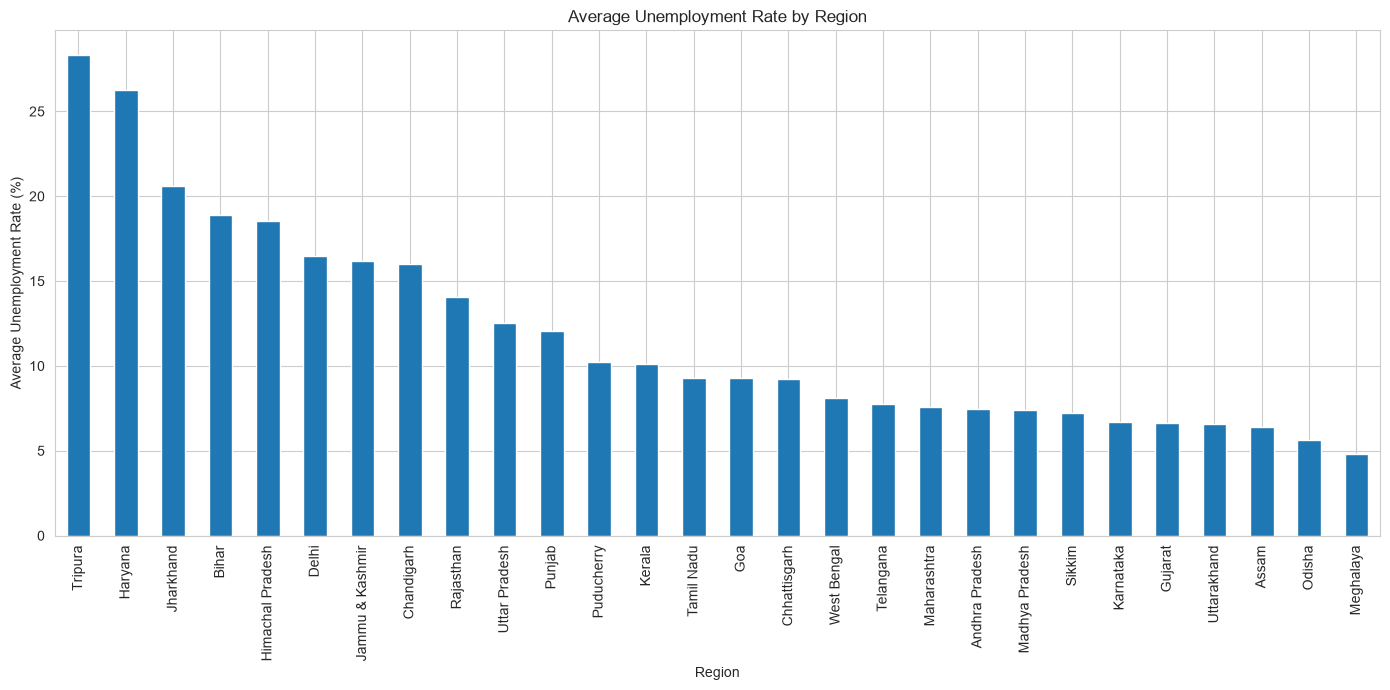

In [6]:
region_analysis = (df.groupby("Region")["Estimated Unemployment Rate (%)"].mean().sort_values(ascending=False))
print("Average Unemployment Rate by Region:")
display(region_analysis)
plt.figure(figsize=(14, 7))
region_analysis.plot(kind="bar")

plt.title("Average Unemployment Rate by Region")
plt.xlabel("Region")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

### 7.Month-wise Trends

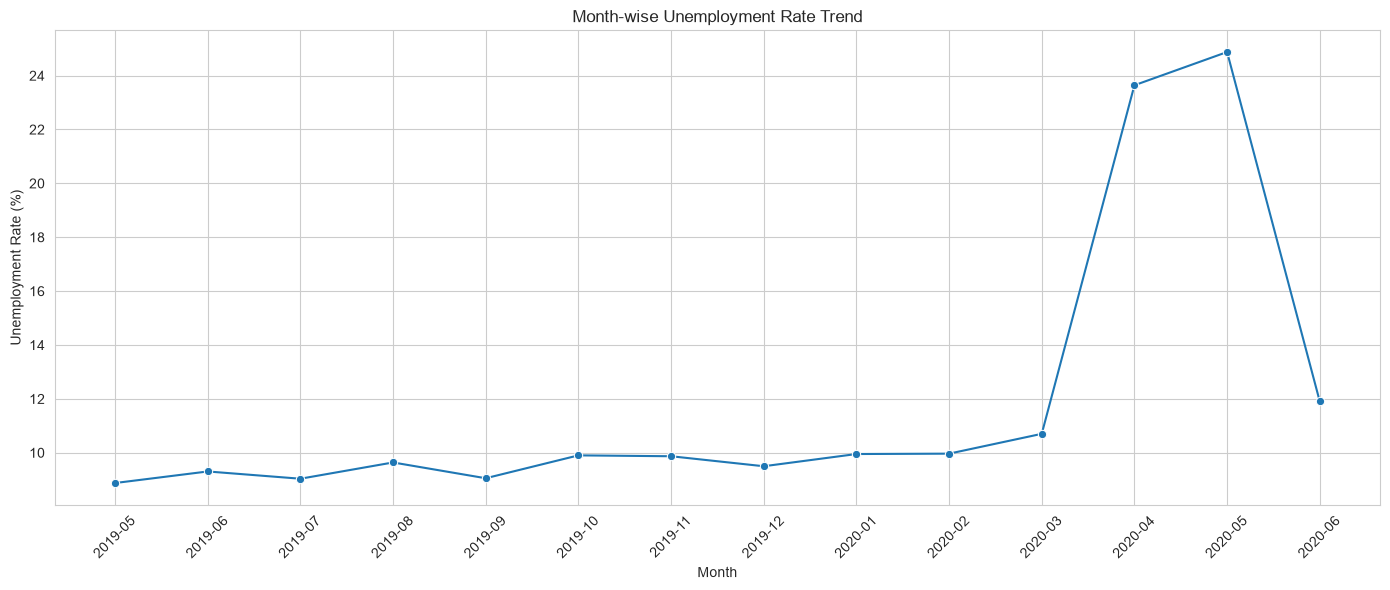

,Month,Estimated Unemployment Rate (%)
0,2019-05,8.874259
1,2019-06,9.303333
2,2019-07,9.033889
3,2019-08,9.637925
4,2019-09,9.051731
5,2019-10,9.900909
6,2019-11,9.868364
7,2019-12,9.497358
8,2020-01,9.950755
9,2020-02,9.964717


In [7]:
monthly_trend = (df.groupby("Month")["Estimated Unemployment Rate (%)"].mean().reset_index())
plt.figure(figsize=(14, 6))
sns.lineplot(data=monthly_trend, x="Month", y="Estimated Unemployment Rate (%)", marker="o")

plt.title("Month-wise Unemployment Rate Trend")
plt.xlabel("Month")
plt.ylabel("Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
display(monthly_trend)

### 8.Three Major States Time-Series Chart

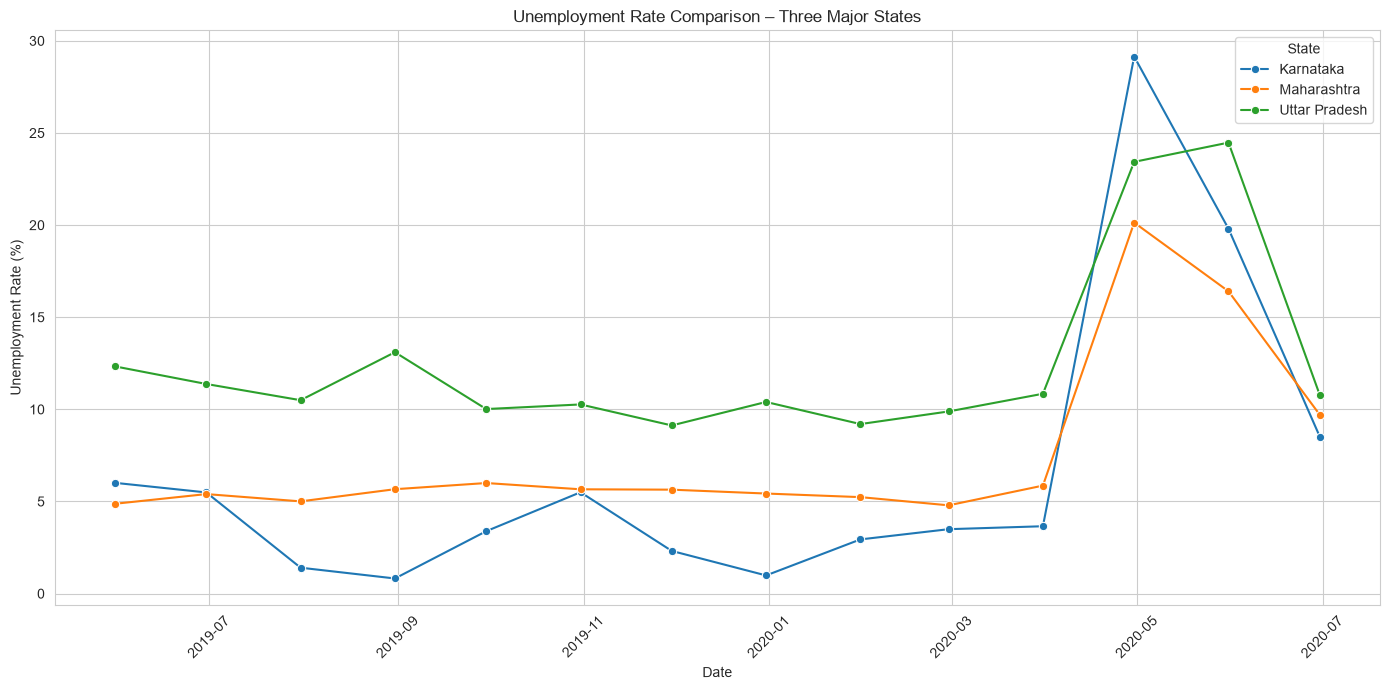

In [8]:
major_states = ["Maharashtra", "Uttar Pradesh", "Karnataka"]
state_data = df[df["Region"].isin(major_states)].copy()
three_state_trend = (state_data.groupby(["Date", "Region"])["Estimated Unemployment Rate (%)"].mean().reset_index())
plt.figure(figsize=(14, 7))
sns.lineplot(data=three_state_trend, x="Date", y="Estimated Unemployment Rate (%)", hue="Region", marker="o")

plt.title("Unemployment Rate Comparison – Three Major States")
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.legend(title="State")
plt.tight_layout()
plt.show()

### 9.Top 10 States Bar Chart

Top 10 Regions with Highest Average Unemployment:


Region
Tripura             28.350357
Haryana             26.283214
Jharkhand           20.585000
Bihar               18.918214
Himachal Pradesh    18.540357
Delhi               16.495357
Jammu & Kashmir     16.188571
Chandigarh          15.991667
Rajasthan           14.058214
Uttar Pradesh       12.551429
Name: Estimated Unemployment Rate (%), dtype: float64

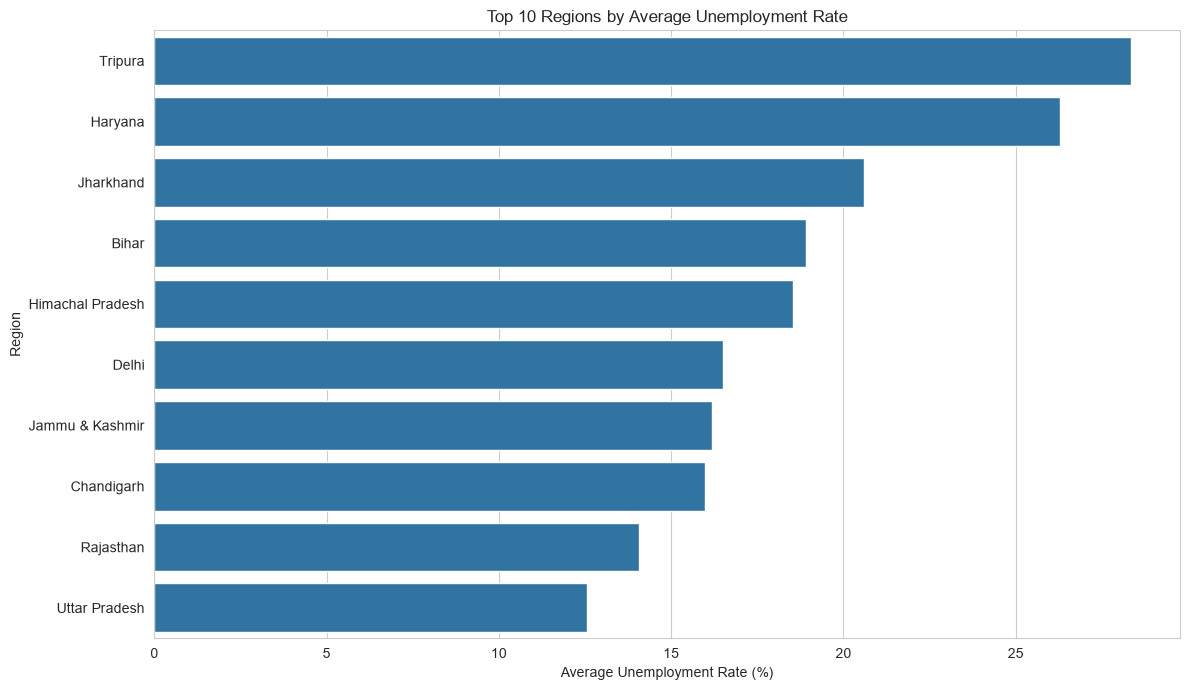

In [9]:
top_10_regions = (df.groupby("Region")["Estimated Unemployment Rate (%)"].mean().sort_values(ascending=False).head(10))
print("Top 10 Regions with Highest Average Unemployment:")
display(top_10_regions)

plt.figure(figsize=(12, 7))
sns.barplot(x=top_10_regions.values, y=top_10_regions.index)

plt.title("Top 10 Regions by Average Unemployment Rate")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("Region")
plt.tight_layout()
plt.show()

### 10.Correlation Heatmap

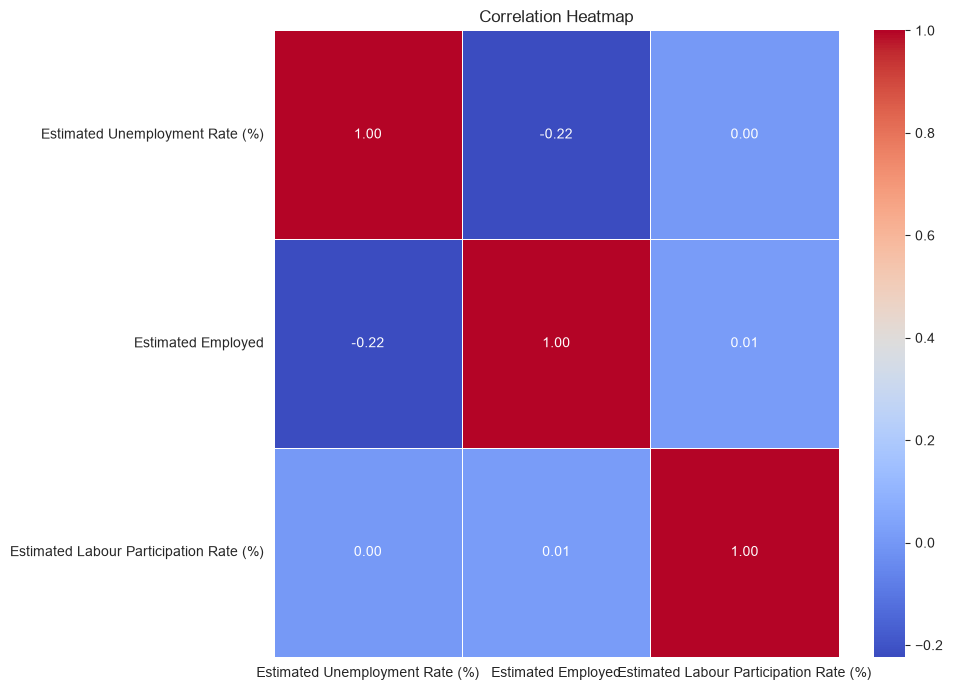

Correlation Matrix:


,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
Estimated Unemployment Rate (%),1.000000,-0.222876,0.002558
Estimated Employed,-0.222876,1.000000,0.011300
Estimated Labour Participation Rate (%),0.002558,0.011300,1.000000


In [10]:
correlation_columns = ["Estimated Unemployment Rate (%)", "Estimated Employed", "Estimated Labour Participation Rate (%)"]
correlation_matrix = df[correlation_columns].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()
print("Correlation Matrix:")
display(correlation_matrix)

### 11.Pre-COVID vs Post-COVID Analysis

COVID Comparison Cutoff Date: 2020-03-01

Pre-COVID Average Unemployment Rate: 9.51 %
Post-COVID Average Unemployment Rate: 17.77 %
Difference: 8.26 percentage points


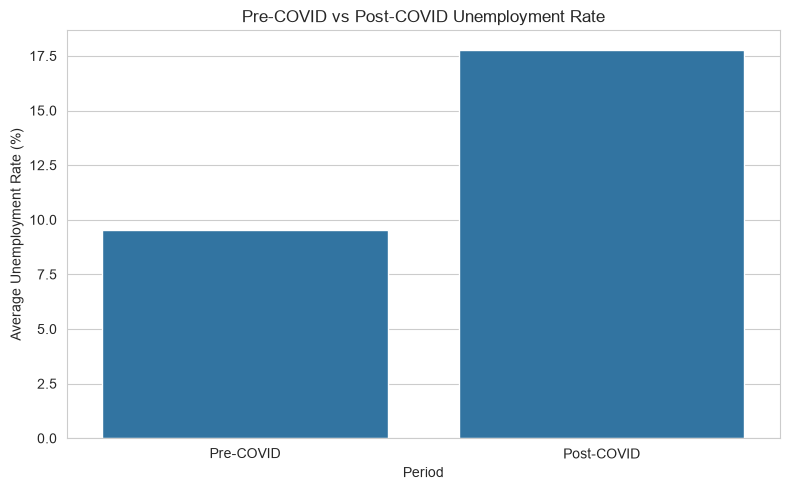

In [11]:
# Common cutoff date for Notebook and Streamlit App
COVID_DATE = pd.Timestamp("2020-03-01")
pre_covid = df[df["Date"] < COVID_DATE]
post_covid = df[df["Date"] >= COVID_DATE]
pre_covid_avg = pre_covid["Estimated Unemployment Rate (%)"].mean()
post_covid_avg = post_covid["Estimated Unemployment Rate (%)"].mean()
difference = post_covid_avg - pre_covid_avg

print("COVID Comparison Cutoff Date:", COVID_DATE.date())
print("\nPre-COVID Average Unemployment Rate:", round(pre_covid_avg, 2), "%")
print("Post-COVID Average Unemployment Rate:", round(post_covid_avg, 2), "%")
print("Difference:", round(difference, 2), "percentage points")

# Visualization
comparison = pd.DataFrame({"Period": ["Pre-COVID", "Post-COVID"], "Average Unemployment Rate": [pre_covid_avg, post_covid_avg]})
plt.figure(figsize=(8, 5))
sns.barplot(data=comparison, x="Period", y="Average Unemployment Rate")

plt.title("Pre-COVID vs Post-COVID Unemployment Rate")
plt.ylabel("Average Unemployment Rate (%)")
plt.tight_layout()
plt.show()

### 12.Written Observations

In [12]:
print("========== PROJECT OBSERVATIONS ==========\n")

print("1. Region-wise Analysis:")
print("Unemployment rates vary across different regions of India.")

print("\n2. Monthly Trends:")
print("Monthly trends show fluctuations in unemployment rates over time.")

print("\n3. Three-State Comparison:")
print("Maharashtra, Uttar Pradesh and Karnataka show different unemployment patterns.")

print("\n4. Top 10 Regions:")
print("The top 10 chart identifies regions with the highest average unemployment rates.")

print("\n5. Correlation Heatmap:")
print("The heatmap shows relationships between unemployment, employment count and labour participation.")

print("\n6. COVID Analysis:")
print("The comparison highlights changes in average unemployment rates before and after March 2020.")

print("\n7. Overall:")
print("These findings describe the available dataset and do not establish the causes of unemployment.")

========== PROJECT OBSERVATIONS ==========

1. Region-wise Analysis:
Unemployment rates vary across different regions of India.

2. Monthly Trends:
Monthly trends show fluctuations in unemployment rates over time.

3. Three-State Comparison:
Maharashtra, Uttar Pradesh and Karnataka show different unemployment patterns.

4. Top 10 Regions:
The top 10 chart identifies regions with the highest average unemployment rates.

5. Correlation Heatmap:
The heatmap shows relationships between unemployment, employment count and labour participation.

6. COVID Analysis:
The comparison highlights changes in average unemployment rates before and after March 2020.

7. Overall:
These findings describe the available dataset and do not establish the causes of unemployment.


### 13.Final Findings

In [13]:
highest_region = region_analysis.idxmax()
lowest_region = region_analysis.idxmin()

highest_rate = region_analysis.max()
lowest_rate = region_analysis.min()

print("========== FINAL PROJECT FINDINGS ==========")

print("\nTotal Records:", len(df))

print("Total Regions:", df["Region"].nunique())

print("Date Range:", df["Date"].min().date(), "to", df["Date"].max().date())

print("\nHighest Average Unemployment Region:", highest_region, "-", round(highest_rate, 2), "%")

print("\nLowest Average Unemployment Region:", lowest_region, "-", round(lowest_rate, 2), "%")

print("\nPre-COVID Average:", round(pre_covid_avg, 2), "%")

print("Post-COVID Average:", round(post_covid_avg, 2), "%")

========== FINAL PROJECT FINDINGS ==========

Total Records: 740
Total Regions: 28
Date Range: 2019-05-31 to 2020-06-30

Highest Average Unemployment Region: Tripura - 28.35 %

Lowest Average Unemployment Region: Meghalaya - 4.8 %

Pre-COVID Average: 9.51 %
Post-COVID Average: 17.77 %


### 14.Cleaned Dataset Export

In [14]:
output_file = "cleaned_unemployment_data.csv"
df.to_csv(output_file, index=False)

print("Cleaned Dataset Exported Successfully!")
print("File Name:", output_file)
print("Final Dataset Shape:", df.shape)

Cleaned Dataset Exported Successfully!
File Name: cleaned_unemployment_data.csv
Final Dataset Shape: (740, 8)
